![display relevant image here](path/url/to/image)
- Banner/header image

# Title
- Relevant to Data and Business Context

## Overview
- BLUF (Bottom Line Up Front)
- One paragraph summary of final model performance and business implications
- Frame your 'story'

## Business Understanding

1. Begin by thoroughly analyzing the business context of FinTech Innovations' loan approval process. Write a short summary that:
- Describes the current manual process and its limitations
- Identifies key stakeholders and their needs
- Explains the implications of different types of model errors
- Justifies your choice between classification and regression approaches

2. Define your modeling goals and success criteria:
- Select appropriate evaluation metrics based on business impact
- You must use at least two different metrics
- Consider creating custom metric
- Establish baseline performance targets
- Document your reasoning for each choice


## Data Understanding
3. Conduct comprehensive exploratory data analysis:
- Describe basic data characteristics
- Examine distributions of all features and target variables
- Investigate relationships between features
- Create visualizations to help aid in EDA
- Document potential data quality issues and their implications

4. Develop feature understanding:
- Categorize features by type (numerical, categorical, ordinal)
- Identify features requiring special preprocessing
- Document missing value patterns and their potential meanings
- Note potential feature engineering opportunities


In [ ]:
# Imports

# Core data handling 
import numpy as np
import pandas as pd
import warnings

# Visualization 
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & pipelines 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer,
)
from sklearn.base import BaseEstimator, TransformerMixin

# Model selection & tuning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    cross_val_score,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
)

# Models: classification (LoanApproved)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Models: regression (RiskScore), if you also model the continuous target 
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    make_scorer,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Feature importance / interpretation
from sklearn.inspection import permutation_importance

# Notebook settings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# EDA Code Here - Create New Cells As Needed
# Load data
df = pd.read_csv("financial_loan_data.csv")


print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nDtypes:")
print(df.dtypes.value_counts())

display(df.head())
display(df.info())

Shape: 20,000 rows x 35 columns
Duplicate rows: 0

Dtypes:
int64      18
float64    10
object      7
Name: count, dtype: int64


,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,"$39,948.00",617,Employed,Master,22,13152,48,Married,2,Own,183,0.3544,1,2,0.3583,No,Home,0,29,9,"7,632.0000",1202,146111,19183,"3,329.0000",0.7250,11,126928,0.1997,0.2276,419.8060,0.1811,0,49.0000
1,38,"$39,709.00",628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.0878,5,3,0.3303,No,Debt Consolidation,0,21,9,"4,627.0000",3460,53204,9595,"3,309.0833",0.9351,3,43609,0.2070,0.2011,794.0542,0.3899,0,52.0000
2,47,"$40,724.00",570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.1374,2,0,0.2447,No,Education,0,20,22,886.0000,895,25176,128874,"3,393.6667",0.8722,6,5205,0.2176,0.2125,666.4067,0.4622,0,52.0000
3,58,"$69,084.00",545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.2676,2,1,0.4362,No,Home,0,27,10,"1,675.0000",1217,104822,5370,"5,757.0000",0.8962,5,99452,0.3004,0.3009,"1,047.5070",0.3131,0,54.0000
4,37,"$103,264.00",594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.3205,0,0,0.0789,No,Debt Consolidation,0,26,27,"1,555.0000",4981,244305,17286,"8,605.3333",0.9414,5,227019,0.1972,0.1760,330.1791,0.0702,1,36.0000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  NumberOfOpenCreditLines     200

None

In [3]:
# AnnualIncome arrives as "$39,948.00" text -> convert to float
df["AnnualIncome"] = (
    df["AnnualIncome"].astype(str).str.replace(r"[$,]", "", regex=True).astype(float)
)

# BankruptcyHistory arrives as Yes/No -> convert to 1/0 (matches PreviousLoanDefaults)
df["BankruptcyHistory"] = df["BankruptcyHistory"].map({"Yes": 1, "No": 0})

print(df[["AnnualIncome", "BankruptcyHistory"]].dtypes)
print(df["BankruptcyHistory"].value_counts(dropna=False))

AnnualIncome         float64
BankruptcyHistory      int64
dtype: object
BankruptcyHistory
0    18952
1     1048
Name: count, dtype: int64


In [ ]:
# Feature categorization
TARGET_CLASS = "LoanApproved"
TARGET_REG = "RiskScore"

# Ordinal: has a natural order
ordinal_features = ["EducationLevel"]
education_order = ["High School", "Associate", "Bachelor", "Master", "Doctorate"]

# Nominal categorical: no order
nominal_features = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]

# Binary flags
binary_features = ["BankruptcyHistory", "PreviousLoanDefaults"]

# Numeric: everything else except targets
numeric_features = [
    c for c in df.columns
    if c not in ordinal_features + nominal_features + binary_features + [TARGET_CLASS, TARGET_REG]
]

feature_types = pd.DataFrame({
    "Type": (["Ordinal"] * len(ordinal_features) + ["Nominal"] * len(nominal_features)
             + ["Binary"] * len(binary_features) + ["Numeric"] * len(numeric_features)),
    "Feature": ordinal_features + nominal_features + binary_features + numeric_features,
})
display(feature_types.groupby("Type")["Feature"].apply(list).to_frame())

,Feature
Type,
Binary,"[BankruptcyHistory, PreviousLoanDefaults]"
Nominal,"[EmploymentStatus, MaritalStatus, HomeOwnershi..."
Numeric,"[Age, AnnualIncome, CreditScore, Experience, L..."
Ordinal,[EducationLevel]


,Missing,Pct
MaritalStatus,1331,6.6550
EducationLevel,901,4.5050
SavingsAccountBalance,572,2.8600



Approval rate by MaritalStatus presence:
MaritalStatus
Present   0.2390
Missing   0.2450

Approval rate by EducationLevel presence:
EducationLevel
Present   0.2500
Missing   0.0000

Approval rate by SavingsAccountBalance presence:
SavingsAccountBalance
Present   0.2380
Missing   0.2640


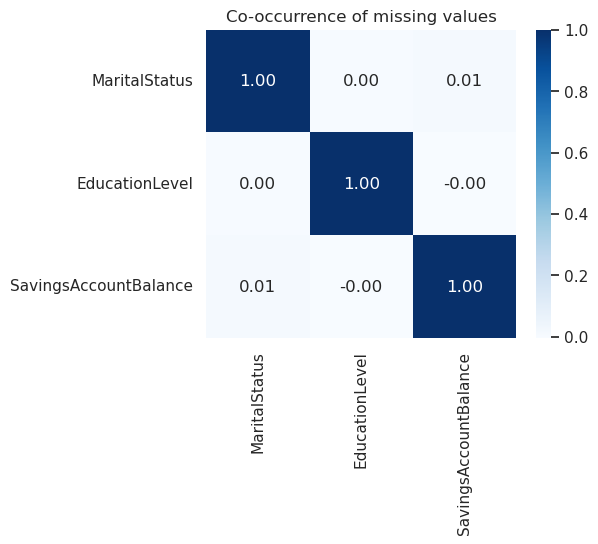

In [ ]:
# Missing value patterns
missing = (
    df.isna().sum().to_frame("Missing")
    .assign(Pct=lambda x: x["Missing"] / len(df) * 100)
    .query("Missing > 0")
    .sort_values("Missing", ascending=False)
)
display(missing)

# Is missingness related to the target? (if so, it is informative, not random)
for col in missing.index:
    rate = df.groupby(df[col].isna())[TARGET_CLASS].mean().rename({False: "Present", True: "Missing"})
    print(f"\nApproval rate by {col} presence:\n{rate.round(3).to_string()}")

# Do missing values co-occur?
miss_corr = df[missing.index].isna().corr()
plt.figure(figsize=(5, 4))
sns.heatmap(miss_corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Co-occurrence of missing values")
plt.show()

In [ ]:
# Descriptive statistics
display(df[numeric_features + binary_features].describe().T)

print("Skewness (|skew| > 1 suggests a log transform):")
skew = df[numeric_features].skew().sort_values(key=abs, ascending=False)
display(skew[abs(skew) > 1].to_frame("Skew"))

,count,mean,std,min,25%,50%,75%,max
Age,"20,000.0000",39.7526,11.6227,18.0000,32.0000,40.0000,48.0000,80.0000
AnnualIncome,"20,000.0000","59,161.4736","40,350.8452","15,000.0000","31,679.0000","48,566.0000","74,391.0000","485,341.0000"
CreditScore,"20,000.0000",571.6124,50.9974,343.0000,540.0000,578.0000,609.0000,712.0000
Experience,"20,000.0000",17.5227,11.3168,0.0000,9.0000,17.0000,25.0000,61.0000
LoanAmount,"20,000.0000","24,882.8678","13,427.4212","3,674.0000","15,575.0000","21,914.5000","30,835.0000","184,732.0000"
LoanDuration,"20,000.0000",54.0570,24.6649,12.0000,36.0000,48.0000,72.0000,120.0000
NumberOfDependents,"20,000.0000",1.5173,1.3863,0.0000,0.0000,1.0000,2.0000,5.0000
MonthlyDebtPayments,"20,000.0000",454.2927,240.5076,50.0000,286.0000,402.0000,564.0000,"2,919.0000"
CreditCardUtilizationRate,"20,000.0000",0.2864,0.1598,0.0010,0.1608,0.2667,0.3906,0.9174
NumberOfOpenCreditLines,"20,000.0000",3.0234,1.7362,0.0000,2.0000,3.0000,4.0000,13.0000


Skewness (|skew| > 1 suggests a log transform):


,Skew
SavingsAccountBalance,6.0961
TotalLiabilities,5.8489
NetWorth,5.5998
TotalAssets,5.3113
CheckingAccountBalance,4.7461
MonthlyLoanPayment,3.0818
TotalDebtToIncomeRatio,2.5745
AnnualIncome,2.0889
MonthlyIncome,1.9929
LoanAmount,1.8337


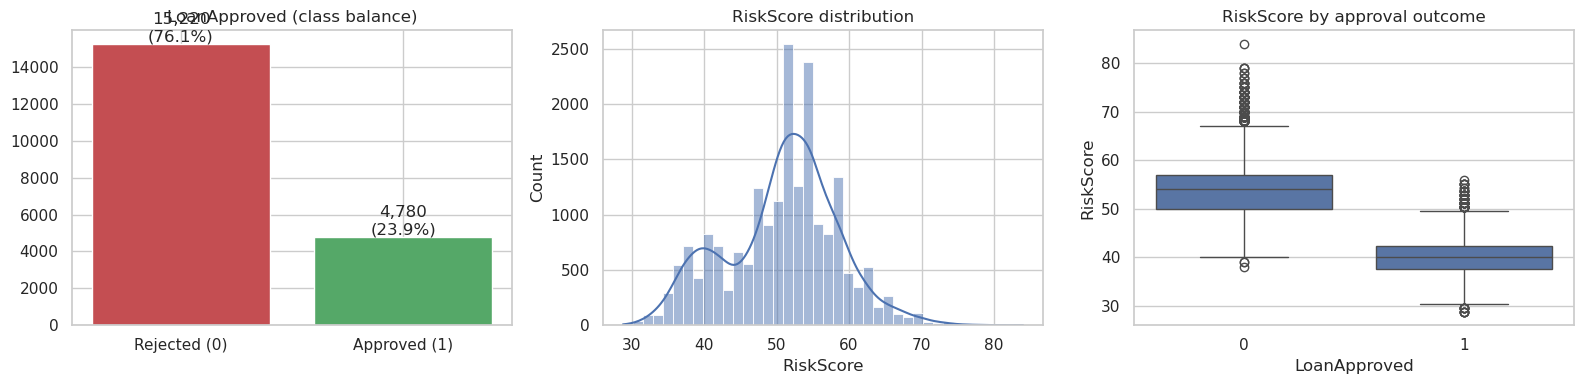

In [ ]:
# Target distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

counts = df[TARGET_CLASS].value_counts().sort_index()
axes[0].bar(["Rejected (0)", "Approved (1)"], counts.values, color=["#c44e52", "#55a868"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("LoanApproved (class balance)")

sns.histplot(df[TARGET_REG], bins=40, kde=True, ax=axes[1])
axes[1].set_title("RiskScore distribution")

sns.boxplot(data=df, x=TARGET_CLASS, y=TARGET_REG, ax=axes[2])
axes[2].set_title("RiskScore by approval outcome")
plt.tight_layout()
plt.show()

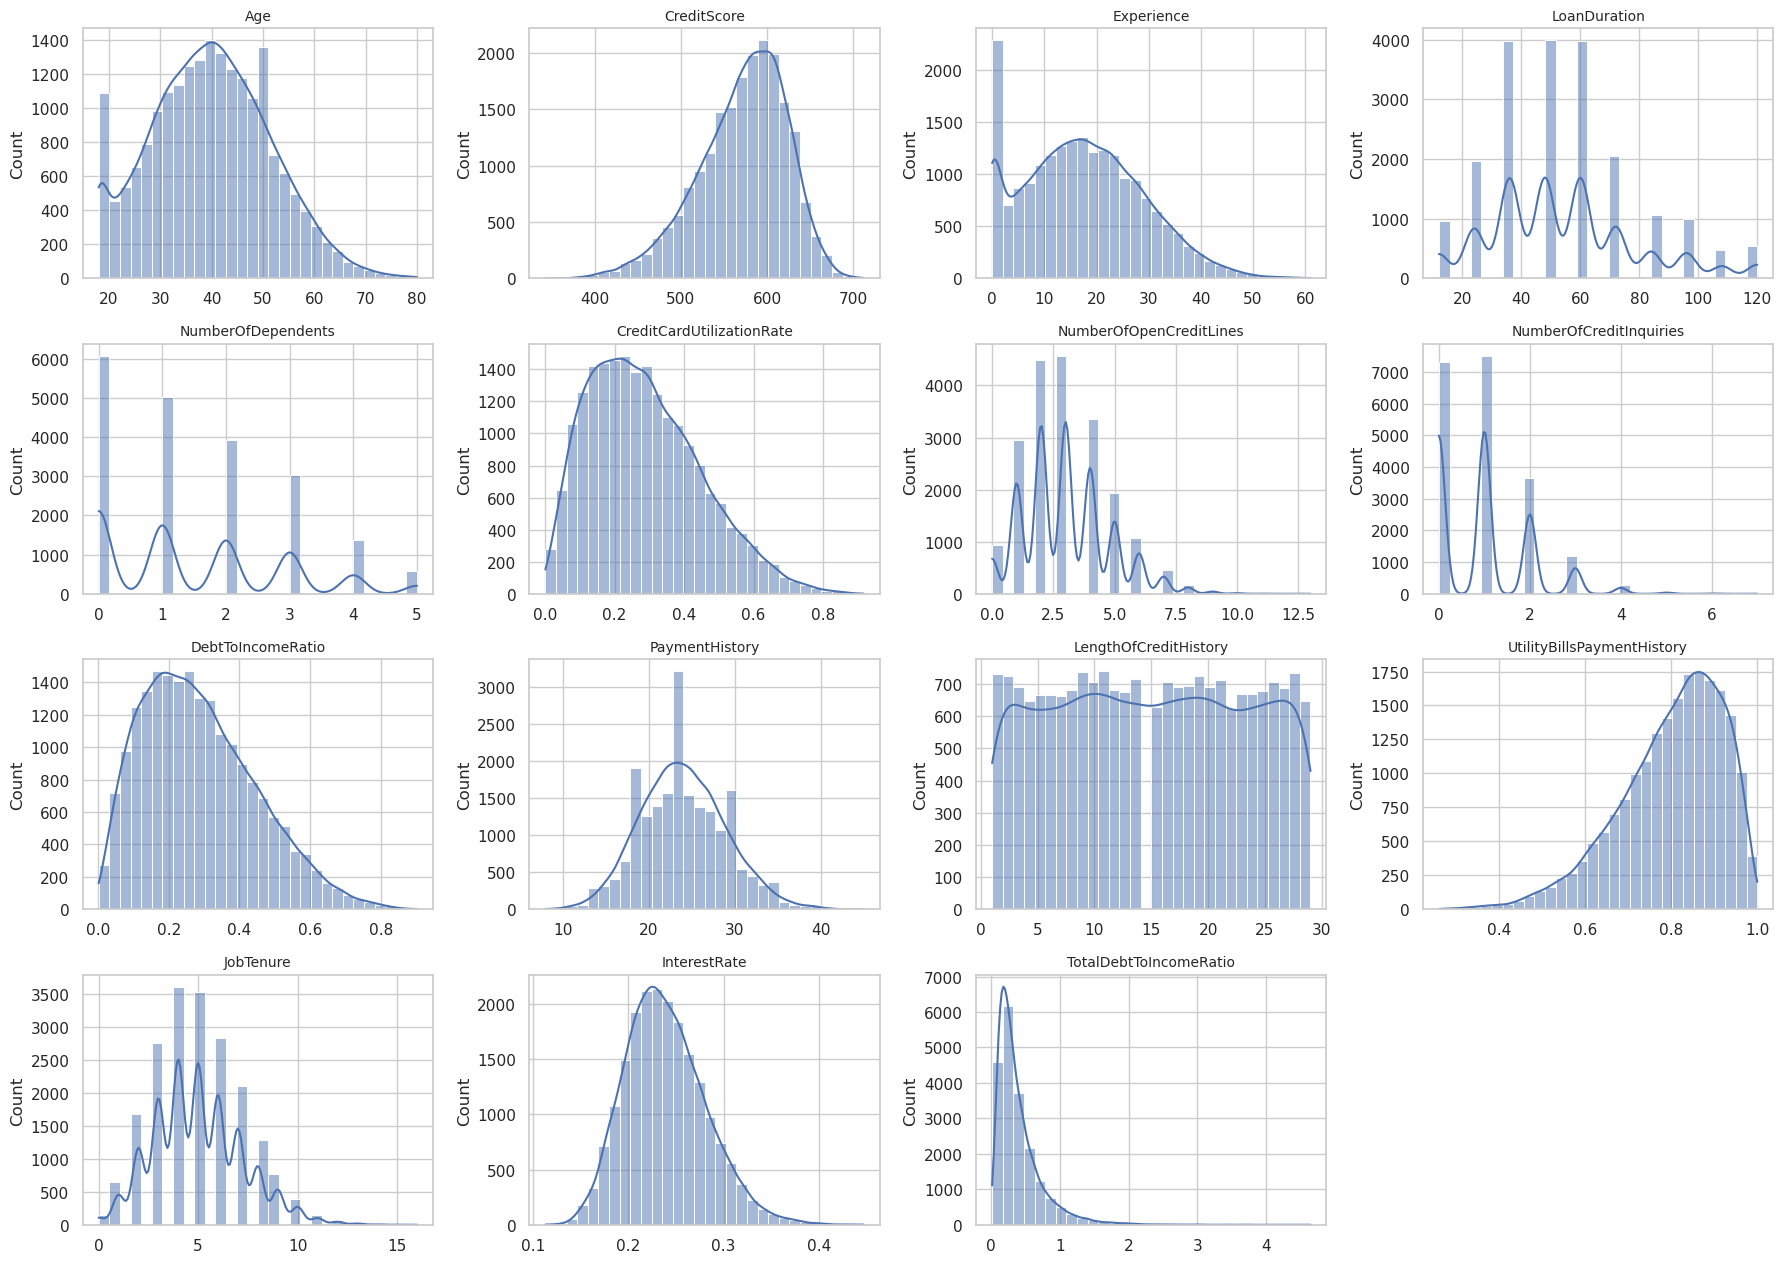

In [ ]:
# Numeric feature distributions
n = len(numeric_features)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

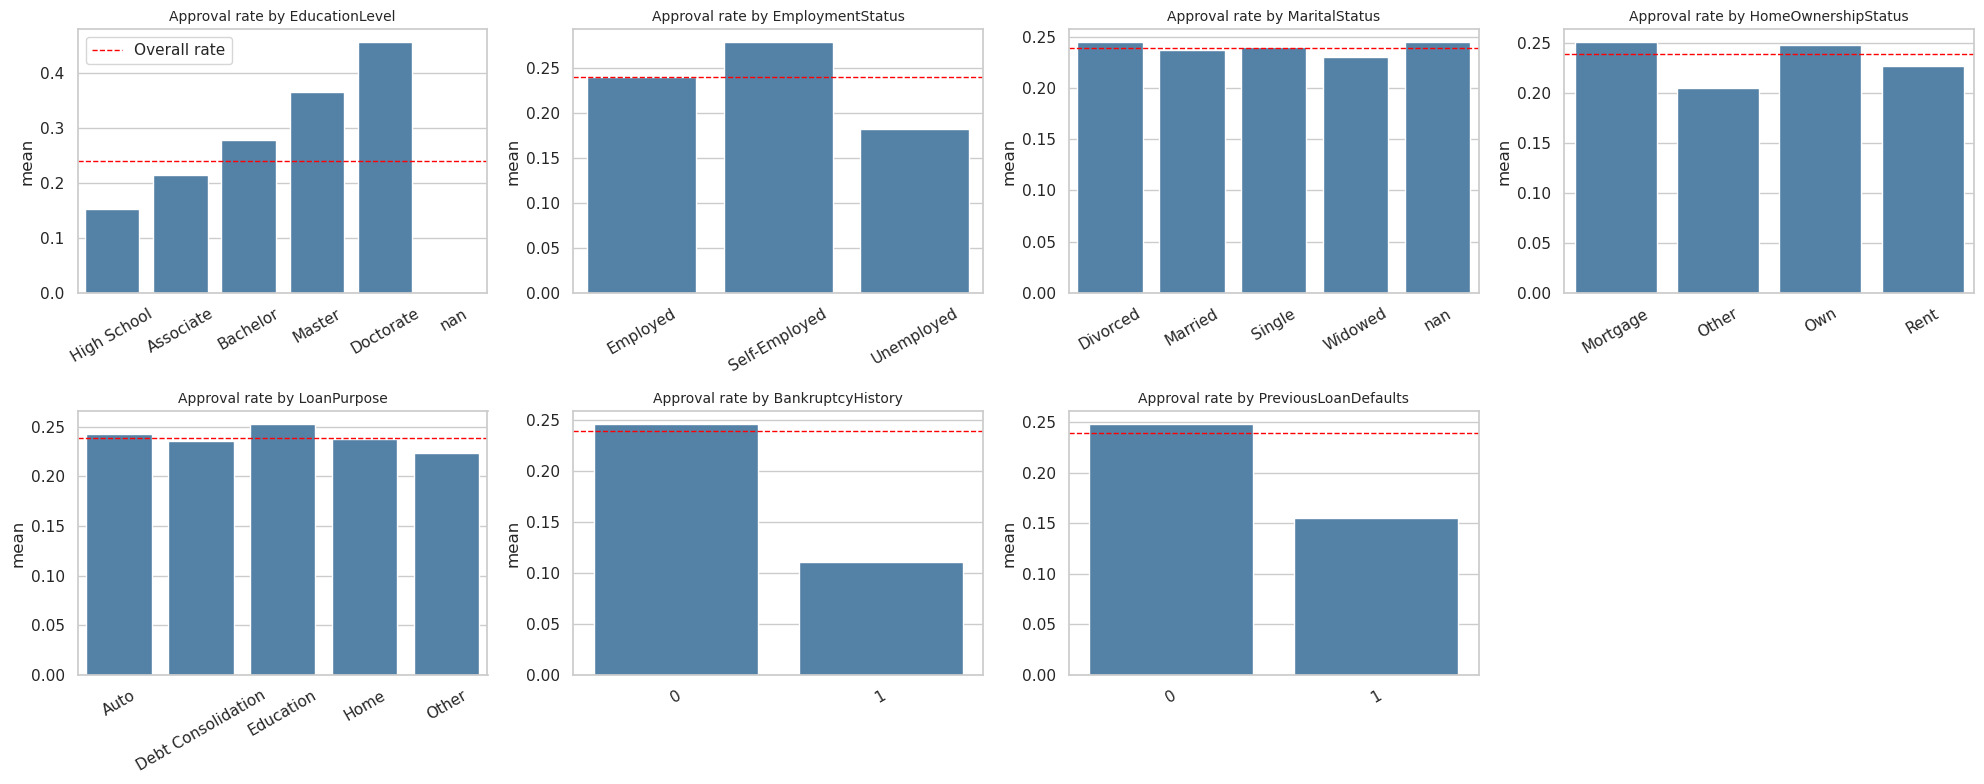

In [ ]:
# Categorical distributions and approval rate per category
cat_cols = ordinal_features + nominal_features + binary_features
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    order = education_order if col == "EducationLevel" else None
    rates = df.groupby(col, dropna=False)[TARGET_CLASS].agg(["mean", "size"])
    if order:
        rates = rates.reindex(order + [np.nan])
    sns.barplot(x=rates.index.astype(str), y=rates["mean"], ax=ax, color="steelblue")
    ax.axhline(df[TARGET_CLASS].mean(), color="red", ls="--", lw=1, label="Overall rate")
    ax.set_title(f"Approval rate by {col}", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

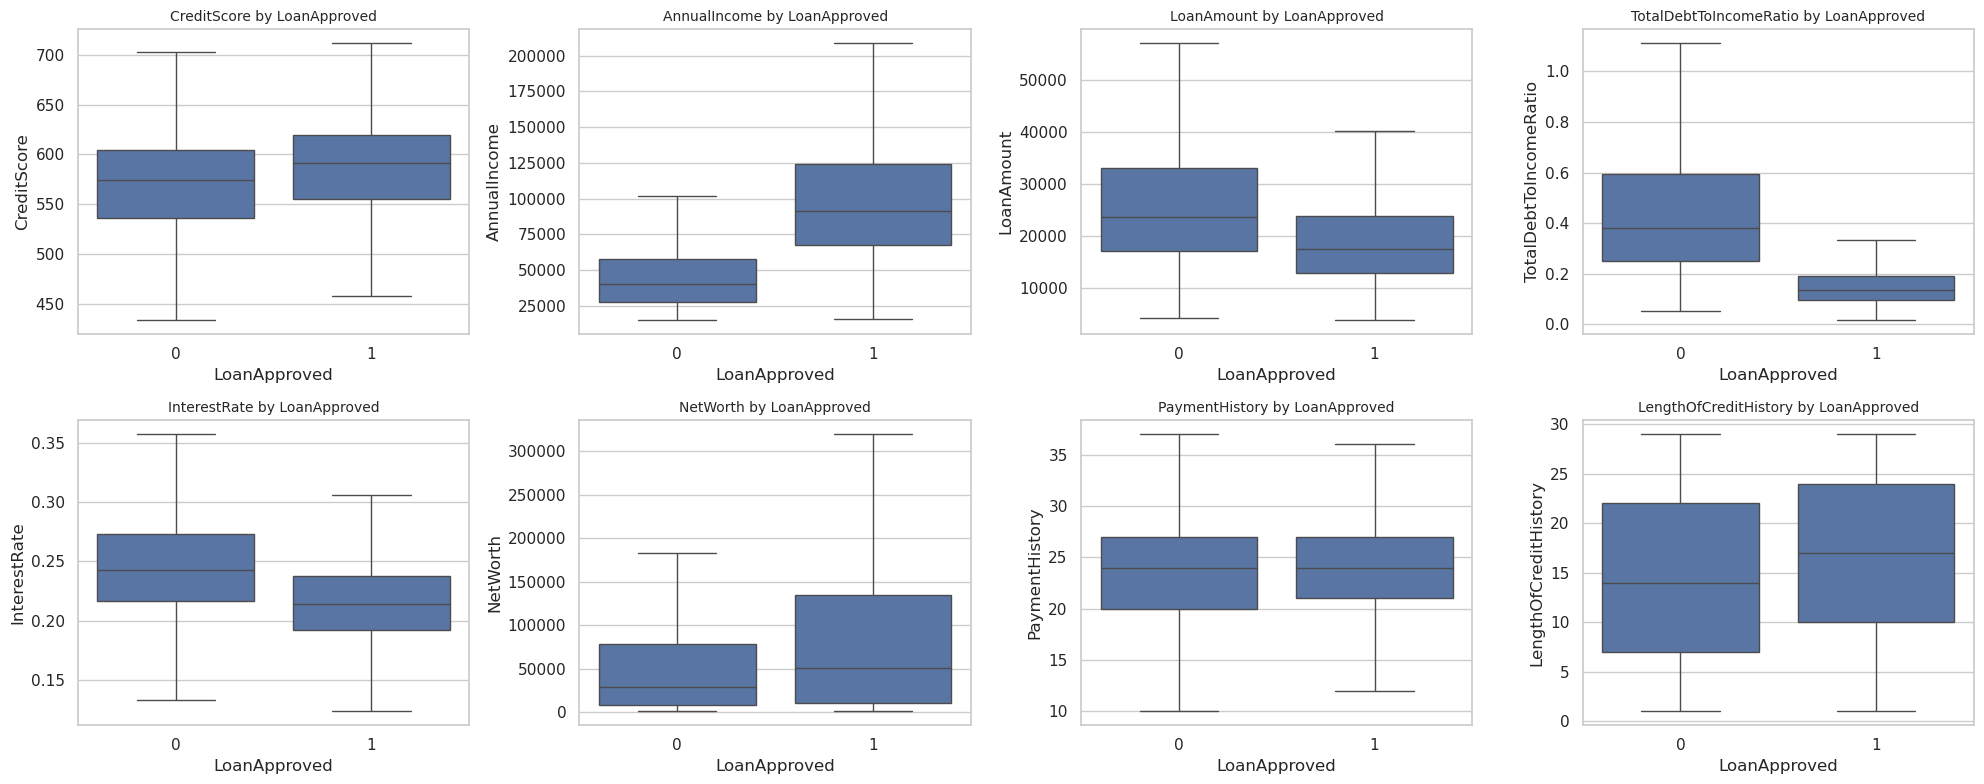

,LoanApproved,RiskScore
MonthlyIncome,0.6041,-0.4870
AnnualIncome,0.5979,-0.4833
TotalDebtToIncomeRatio,-0.4104,0.3426
InterestRate,-0.3016,0.2682
BaseInterestRate,-0.2473,0.2562
LoanAmount,-0.2395,0.1380
NetWorth,0.1879,-0.3043
MonthlyLoanPayment,-0.1843,0.1155
TotalAssets,0.1840,-0.2971
CreditScore,0.1420,-0.2402


In [10]:
# Numeric features split by approval outcome
key_numeric = ["CreditScore", "AnnualIncome", "LoanAmount", "TotalDebtToIncomeRatio",
               "InterestRate", "NetWorth", "PaymentHistory", "LengthOfCreditHistory"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.boxplot(data=df, x=TARGET_CLASS, y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} by LoanApproved", fontsize=10)
plt.tight_layout()
plt.show()

# Correlation of every numeric feature with both targets
target_corr = (
    df[numeric_features + binary_features + [TARGET_CLASS, TARGET_REG]]
    .corr()[[TARGET_CLASS, TARGET_REG]]
    .drop([TARGET_CLASS, TARGET_REG])
    .sort_values(TARGET_CLASS, key=abs, ascending=False)
)
display(target_corr.head(15))

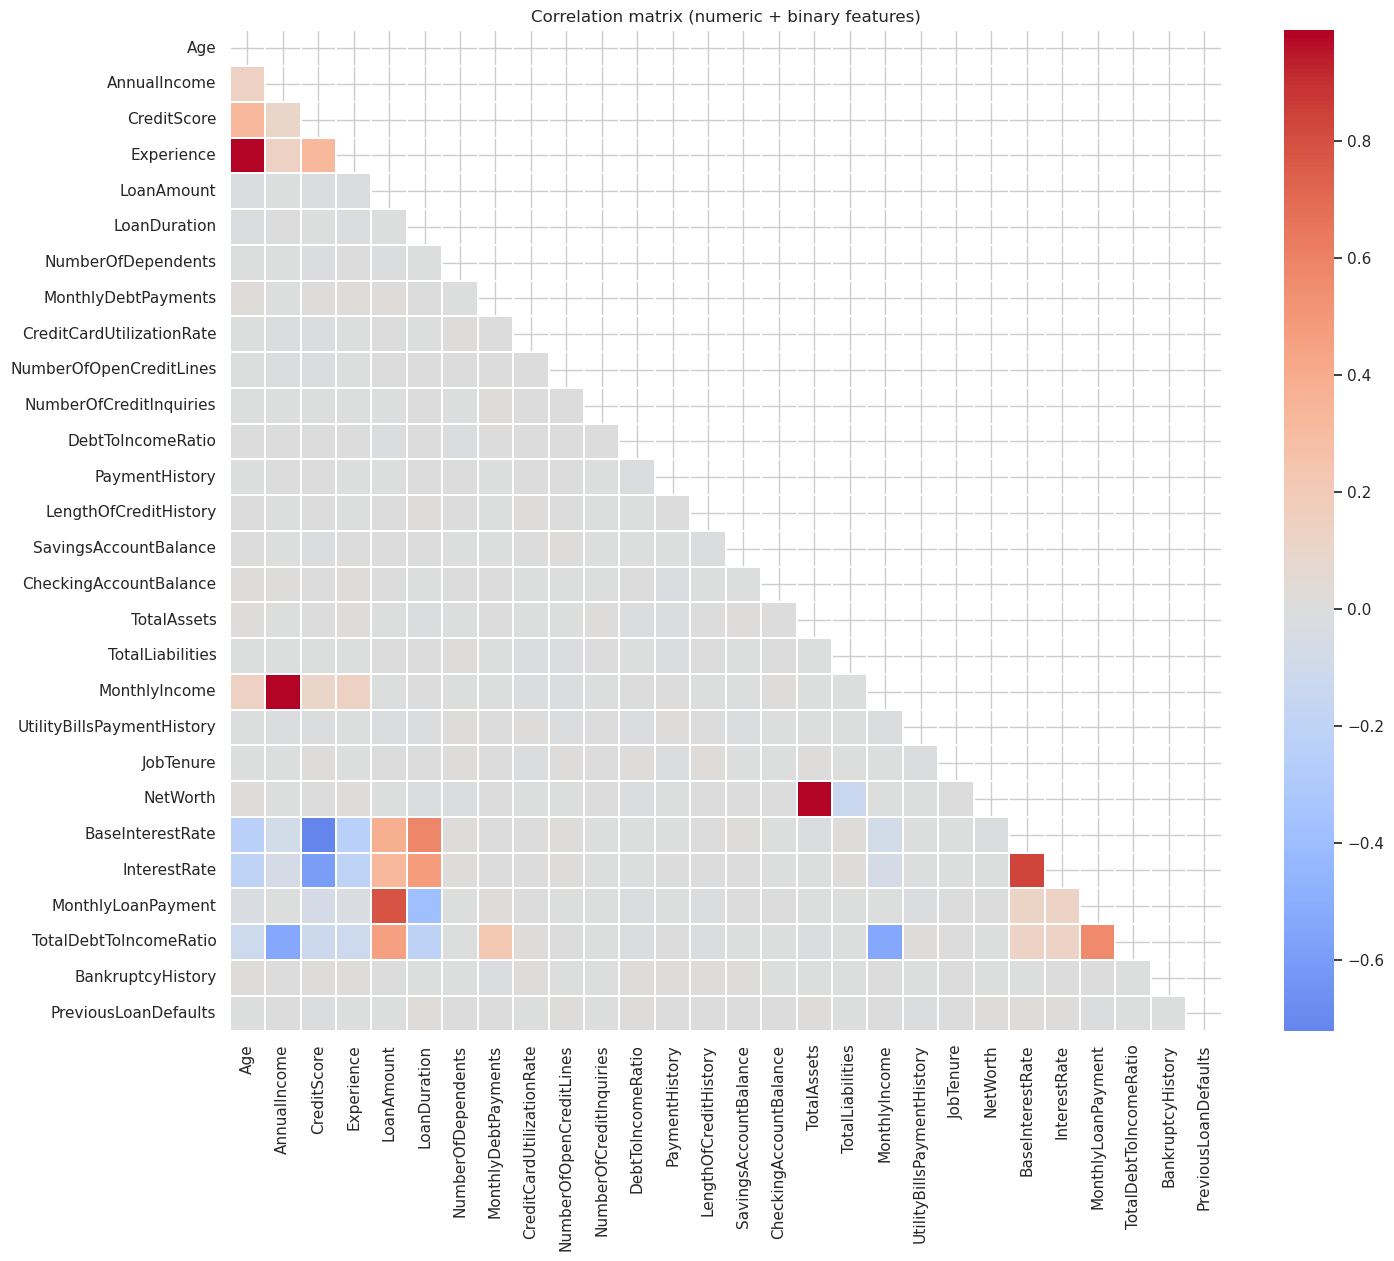

,Feature A,Feature B,corr
154,MonthlyIncome,AnnualIncome,0.9899
3,Experience,Age,0.9830
226,NetWorth,TotalAssets,0.9790
275,InterestRate,BaseInterestRate,0.8346
280,MonthlyLoanPayment,LoanAmount,0.7808
233,BaseInterestRate,CreditScore,-0.7226


In [ ]:
#Feature-to-feature relationships and multicollinearity
corr = df[numeric_features + binary_features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=False, linewidths=0.2)
plt.title("Correlation matrix (numeric + binary features)")
plt.show()

# Strongly correlated pairs (candidates to drop for linear models)
pairs = (
    corr.where(~mask).stack().rename("corr").reset_index()
    .rename(columns={"level_0": "Feature A", "level_1": "Feature B"})
)
display(pairs[abs(pairs["corr"]) > 0.7].sort_values("corr", key=abs, ascending=False))

In [12]:
# IQR-based outlier rate per numeric feature
def iqr_outlier_pct(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

outliers = df[numeric_features].apply(iqr_outlier_pct).sort_values(ascending=False)
display(outliers[outliers > 1].round(2).to_frame("Outlier %"))

# Logical consistency checks
checks = {
    "TotalAssets < Savings + Checking": (df["TotalAssets"] < df["SavingsAccountBalance"].fillna(0) + df["CheckingAccountBalance"]).sum(),
    "Experience > Age - 18": (df["Experience"] > df["Age"] - 18).sum(),
    "Negative NetWorth": (df["NetWorth"] < 0).sum(),
    "LoanAmount <= 0": (df["LoanAmount"] <= 0).sum(),
    "CreditScore outside 300-850": (~df["CreditScore"].between(300, 850)).sum(),
    "Utilization or DTI outside 0-1": ((~df["CreditCardUtilizationRate"].between(0, 1)) | (~df["DebtToIncomeRatio"].between(0, 1))).sum(),
}
display(pd.Series(checks, name="Violations").to_frame())

,Outlier %
NetWorth,7.8200
SavingsAccountBalance,7.7400
TotalLiabilities,7.6600
CheckingAccountBalance,7.6100
TotalAssets,7.2100
TotalDebtToIncomeRatio,5.7600
MonthlyLoanPayment,5.4400
AnnualIncome,4.7400
MonthlyIncome,4.6200
LoanAmount,3.7300


,Violations
TotalAssets < Savings + Checking,0
Experience > Age - 18,0
Negative NetWorth,0
LoanAmount <= 0,0
CreditScore outside 300-850,0
Utilization or DTI outside 0-1,0


In [13]:
# RiskScore is computed from LoanApproved in the generator script (x0.8 if approved),
# so it cannot be used as a predictor of LoanApproved.
print("Correlation RiskScore vs LoanApproved:",
      round(df[TARGET_REG].corr(df[TARGET_CLASS]), 3))

# Candidate engineered features (quick sanity check of signal)
eng = pd.DataFrame({
    "LoanToIncome": df["LoanAmount"] / df["AnnualIncome"],
    "PaymentToIncome": df["MonthlyLoanPayment"] / df["MonthlyIncome"],
    "AssetCoverage": df["TotalAssets"] / (df["TotalLiabilities"] + 1),
    "LogLoanAmount": np.log1p(df["LoanAmount"]),
})
display(eng.corrwith(df[TARGET_CLASS]).to_frame("Corr with LoanApproved"))

Correlation RiskScore vs LoanApproved: -0.766


,Corr with LoanApproved
LoanToIncome,-0.4144
PaymentToIncome,-0.3576
AssetCoverage,0.1075
LogLoanAmount,-0.2596


## Data Preparation
5. Design your preprocessing strategy:
- Create separate preprocessing flows for different feature types
- Must utilize ColumnTransformer and Pipeline
- Consider using FeatureUnion as well
- Handle missing values appropriately for each feature
- Handle Categorical and Ordinal data appropriately
- Scale numeric values if model requires it (linear model)
- Document your reasoning for each preprocessing decision



In [14]:
# Data Prep Code Here - Create New Cells As Needed
# Assumes `df` already has AnnualIncome -> float and BankruptcyHistory -> 0/1 from the EDA cells
TARGET = "LoanApproved"

# RiskScore is computed from LoanApproved in CSV_Generation.py (x0.8 if approved) -> target leakage
LEAKY = ["RiskScore"]

# Near-duplicates: MonthlyIncome = AnnualIncome/12 (corr 0.99); BaseInterestRate vs InterestRate (corr 0.83)
REDUNDANT = ["MonthlyIncome", "BaseInterestRate"]

X = df.drop(columns=[TARGET] + LEAKY + REDUNDANT)
y = df[TARGET]

# Split BEFORE fitting any transformer so no test information leaks into imputers or scalers.
# Stratify because only ~24% of applications are approved.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Approval rate -> train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: (16000, 31) | Test: (4000, 31)
Approval rate -> train: 0.239 | test: 0.239


In [ ]:
# Custom feature engineering transformer
class RatioFeatures(BaseEstimator, TransformerMixin):
    """Adds affordability ratios. Stateless, so it is safe inside a Pipeline and cross-validation."""

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        X["LoanToIncome"] = X["LoanAmount"] / X["AnnualIncome"].replace(0, np.nan)
        X["AssetCoverage"] = X["TotalAssets"] / (X["TotalLiabilities"] + 1)
        X["PaymentToIncome"] = X["MonthlyLoanPayment"] / (X["AnnualIncome"] / 12).replace(0, np.nan)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.r_[self.feature_names_in_, ["LoanToIncome", "AssetCoverage", "PaymentToIncome"]]

In [ ]:
# Feature groups
ordinal_features = ["EducationLevel"]
education_order = [["High School", "Associate", "Bachelor", "Master", "Doctorate"]]

nominal_features = ["EmploymentStatus", "MaritalStatus", "HomeOwnershipStatus", "LoanPurpose"]
binary_features = ["BankruptcyHistory", "PreviousLoanDefaults"]

# Right-skewed money features (skew 1.7 to 6.1 in EDA) -> log1p. Values are non-negative, so log1p is safe.
log_features = [
    "AnnualIncome", "LoanAmount", "MonthlyDebtPayments", "SavingsAccountBalance",
    "CheckingAccountBalance", "TotalAssets", "TotalLiabilities", "NetWorth",
    "MonthlyLoanPayment", "LoanToIncome", "AssetCoverage", "PaymentToIncome",  # last 3 are engineered
]

numeric_features = [
    c for c in X.columns
    if c not in ordinal_features + nominal_features + binary_features + log_features
]
print("Plain numeric:", numeric_features)

Plain numeric: ['Age', 'CreditScore', 'Experience', 'LoanDuration', 'NumberOfDependents', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'PaymentHistory', 'LengthOfCreditHistory', 'UtilityBillsPaymentHistory', 'JobTenure', 'InterestRate', 'TotalDebtToIncomeRatio']


In [17]:
from sklearn.impute import MissingIndicator

In [18]:
# Plain numeric: median impute -> scale
num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Skewed numeric: FeatureUnion of (a) impute -> log1p -> scale and (b) a flag marking imputed rows.
# The flag matters for SavingsAccountBalance, which has 572 missing values.
log_pipe = FeatureUnion([
    ("values", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])),
    ("missing_flag", MissingIndicator(features="missing-only")),
])

# Ordinal: encode with the true order. Impute the mode, but keep a missing flag
# (see note below: missing EducationLevel is not random).
ord_pipe = FeatureUnion([
    ("values", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ord", OrdinalEncoder(categories=education_order)),
        ("scale", StandardScaler()),
    ])),
    ("missing_flag", MissingIndicator(features="missing-only")),
])

# Nominal: missing becomes its own "Unknown" category, then one-hot.
# handle_unknown="ignore" keeps the pipeline from crashing on unseen categories at predict time.
nom_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Binary 0/1 flags: no scaling needed
bin_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent"))])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipe, numeric_features),
        ("log", log_pipe, log_features),
        ("ord", ord_pipe, ordinal_features),
        ("nom", nom_pipe, nominal_features),
        ("bin", bin_pipe, binary_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Full preprocessing pipeline: engineer ratios first, then transform by feature type.
# Later cells append a model step: Pipeline([("prep", prep), ("model", ...)])
prep = Pipeline([
    ("ratios", RatioFeatures()),
    ("preprocess", preprocessor),
])
prep

Pipeline(steps=[('ratios', RatioFeatures()),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'CreditScore',
                                                   'Experience', 'LoanDuration',
                                                   'NumberOfDependents',
                                                   'CreditCardUtilizationRate',
                                                   'NumberOfOpenCreditLines',
                                                   'NumberOfCreditInquiries',
                                                   'DebtToIncomeRatio...
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('ohe',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['EmploymentStatus',
                                                   'MaritalStatus',
                                                   'HomeOwnershipStatus',
                                                   'LoanPurpose']),
                                                 ('bin',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['BankruptcyHistory',
                                                   'PreviousLoanDefaults'])],
                                   verbose_feature_names_out=False))])

In [19]:
X_train_prep = prep.fit_transform(X_train)   # fit on train only
X_test_prep = prep.transform(X_test)         # transform only on test
feature_names = prep.named_steps["preprocess"].get_feature_names_out()

print(f"Train: {X_train_prep.shape} | Test: {X_test_prep.shape}")
print(f"NaNs -> train: {np.isnan(X_train_prep).sum()} | test: {np.isnan(X_test_prep).sum()}")
print(f"Infs -> train: {np.isinf(X_train_prep).sum()}")

display(pd.DataFrame(X_train_prep, columns=feature_names).describe().T.head(10))

Train: (16000, 49) | Test: (4000, 49)
NaNs -> train: 0 | test: 0
Infs -> train: 0


,count,mean,std,min,25%,50%,75%,max
Age,"16,000.0000",-0.0000,1.0000,-1.8647,-0.7492,0.0231,0.7096,3.4555
CreditScore,"16,000.0000",0.0000,1.0000,-4.4798,-0.6192,0.1255,0.7330,2.7516
Experience,"16,000.0000",-0.0000,1.0000,-1.5444,-0.7506,-0.0450,0.6606,3.8358
LoanDuration,"16,000.0000",-0.0000,1.0000,-1.7083,-0.7329,-0.2452,0.7302,2.6809
NumberOfDependents,"16,000.0000",-0.0000,1.0000,-1.0908,-1.0908,-0.3704,0.3499,2.5109
CreditCardUtilizationRate,"16,000.0000",0.0000,1.0000,-1.7717,-0.7869,-0.1258,0.6540,3.9429
NumberOfOpenCreditLines,"16,000.0000",-0.0000,1.0000,-1.7378,-0.5877,-0.0127,0.5623,5.7377
NumberOfCreditInquiries,"16,000.0000",0.0000,1.0000,-1.0062,-1.0062,0.0105,1.0273,6.1108
DebtToIncomeRatio,"16,000.0000",-0.0000,1.0000,-1.7714,-0.7777,-0.1343,0.6475,3.8501
PaymentHistory,"16,000.0000",0.0000,1.0000,-3.2510,-0.6107,-0.0013,0.6080,4.2638


## Modeling
6. Implement your modeling approach:
- Choose appropriate model algorithms based on your problem definition
- Set up validation strategy with chosen metrics
- Use a train test split and cross validation
- Create complete pipeline including any preprocessing and model
- Document your reasoning for each modeling decision

7. Optimize your model:
- Define parameter grid based on your understanding of the algorithms
- Implement GridSearchCV and/or RandomizedSearchCV with chosen metrics
- Consider tuning preprocessing steps
- Track and document the impact of different parameter combinations
- Consider the trade-offs between different model configurations

NOTE: Be mindful of time considerations - showcase “how to tune” 


In [20]:
#  Modeling Code Here - Create New Cells as Needed

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
import time

# Custom metric: wrongly approving a loan that should be rejected costs far more than
# wrongly rejecting a good applicant (a default loses principal, a lost applicant loses margin).
# Assumption: 5:1. Replace with FinTech Innovations' real figures if available.
COST_FP = 5   # predicted approve, true reject
COST_FN = 1   # predicted reject, true approve

def business_cost(y_true, y_pred):
    """Average misclassification cost per applicant (lower is better)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (COST_FP * fp + COST_FN * fn) / len(y_true)

cost_scorer = make_scorer(business_cost, greater_is_better=False)

# Validation strategy: 5-fold stratified CV on the training set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "roc_auc": "roc_auc",          # ranking quality, independent of threshold
    "f1": "f1",                    # balance of precision/recall on the 24% positive class
    "precision": "precision",      # of loans we approve, how many should be approved
    "recall": "recall",            # of good applicants, how many we approve
    "neg_cost": cost_scorer,       # custom business metric (sign flipped by sklearn)
}

In [ ]:
# Baseline and model comparison
models = {
    "Dummy (baseline)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([("prep", prep), ("model", model)])   # preprocessing is refit inside every fold
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name,
                 **{m: res[f"test_{m}"].mean() for m in scoring},
                 "Seconds": time.time() - start})

comparison = pd.DataFrame(rows).set_index("Model")
comparison["cost_per_applicant"] = -comparison.pop("neg_cost")
display(comparison.round(3))

,roc_auc,f1,precision,recall,Seconds,cost_per_applicant
Model,,,,,,
Dummy (baseline),0.5000,0.2390,0.2390,0.2400,2.6010,1.0970
Logistic Regression,0.9880,0.8790,0.8150,0.9550,1.9620,0.2700
Random Forest,0.9780,0.8410,0.8870,0.7990,12.9350,0.1700
HistGradientBoosting,0.9900,0.8980,0.9100,0.8860,2.8870,0.1320


In [22]:
# Logistic regression: tune regularization strength (fast)
lr_pipe = Pipeline([("prep", prep),
                    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))])
lr_grid = {"model__C": [0.01, 0.1, 1, 10]}

lr_search = GridSearchCV(lr_pipe, lr_grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
print(f"LogReg best: {lr_search.best_params_} | CV ROC-AUC {lr_search.best_score_:.4f}")

# Gradient boosting: tune learning rate, tree depth, regularization (~30 seconds)
hgb_pipe = Pipeline([("prep", prep),
                     ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
hgb_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, None],
    "model__l2_regularization": [0, 1.0],
}

hgb_search = GridSearchCV(hgb_pipe, hgb_grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1)
hgb_search.fit(X_train, y_train)
print(f"HistGB best: {hgb_search.best_params_} | CV ROC-AUC {hgb_search.best_score_:.4f}")

LogReg best: {'model__C': 10} | CV ROC-AUC 0.9878
HistGB best: {'model__l2_regularization': 0, 'model__learning_rate': 0.1, 'model__max_depth': None} | CV ROC-AUC 0.9901


,params,mean_test_roc_auc,mean_test_f1,mean_test_recall,cost_per_applicant
3,"{'model__l2_regularization': 0, 'model__learni...",0.9900,0.8980,0.8860,0.1320
7,"{'model__l2_regularization': 1.0, 'model__lear...",0.9900,0.9000,0.8870,0.1280
1,"{'model__l2_regularization': 0, 'model__learni...",0.9870,0.8830,0.8690,0.1490
5,"{'model__l2_regularization': 1.0, 'model__lear...",0.9870,0.8830,0.8670,0.1470
2,"{'model__l2_regularization': 0, 'model__learni...",0.9860,0.8780,0.8560,0.1480
6,"{'model__l2_regularization': 1.0, 'model__lear...",0.9860,0.8780,0.8570,0.1490
0,"{'model__l2_regularization': 0, 'model__learni...",0.9780,0.8440,0.8150,0.1840
4,"{'model__l2_regularization': 1.0, 'model__lear...",0.9780,0.8430,0.8140,0.1850


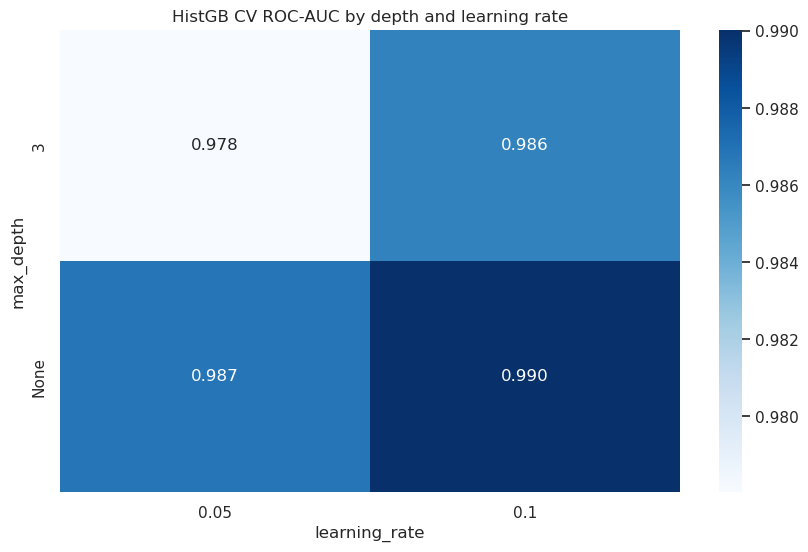

In [ ]:
# Track the impact of each parameter combination
results = pd.DataFrame(hgb_search.cv_results_)
tuning_table = (
    results[["params", "mean_test_roc_auc", "mean_test_f1", "mean_test_recall", "mean_test_neg_cost"]]
    .assign(cost_per_applicant=lambda d: -d["mean_test_neg_cost"])
    .drop(columns="mean_test_neg_cost")
    .sort_values("mean_test_roc_auc", ascending=False)
)
display(tuning_table.round(3))

# Impact of depth and learning rate (averaged over the other settings)
results["max_depth"] = results["param_model__max_depth"].astype(str)
results["learning_rate"] = results["param_model__learning_rate"]
sns.heatmap(results.pivot_table(index="max_depth", columns="learning_rate", values="mean_test_roc_auc"),
            annot=True, fmt=".3f", cmap="Blues")
plt.title("HistGB CV ROC-AUC by depth and learning rate")
plt.show()

Cost-optimal threshold: 0.85
Cost at 0.50: 0.132 -> at 0.85: 0.086
F1 at 0.85: 0.818


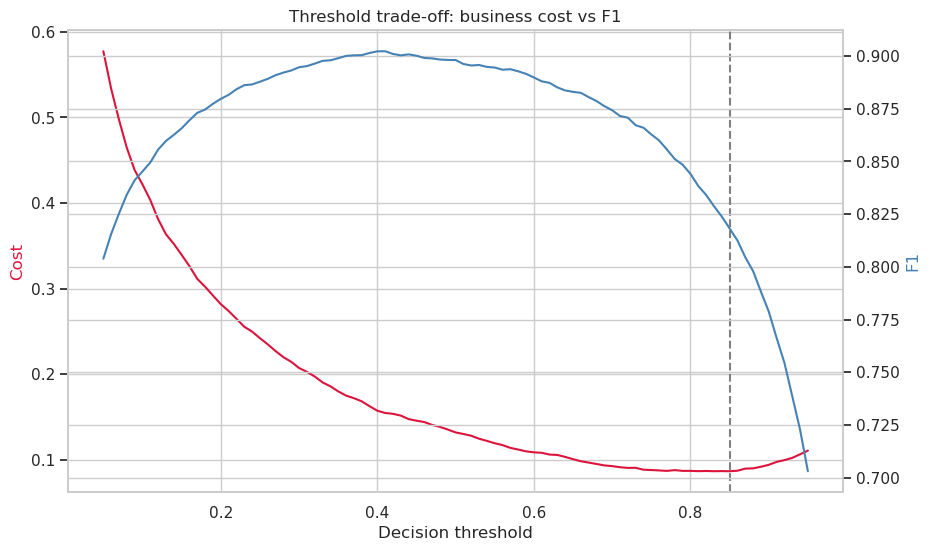

In [ ]:
# Pick the final model and the cost-optimal threshold
final_model = hgb_search.best_estimator_

# Out-of-fold probabilities on the TRAINING set, so the threshold is chosen without touching the test set
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
costs = [business_cost(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
f1s = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]

print(f"Cost-optimal threshold: {best_threshold:.2f}")
print(f"Cost at 0.50: {business_cost(y_train, (oof_proba >= 0.5).astype(int)):.3f} "
      f"-> at {best_threshold:.2f}: {min(costs):.3f}")
print(f"F1 at {best_threshold:.2f}: {f1_score(y_train, (oof_proba >= best_threshold).astype(int)):.3f}")

fig, ax1 = plt.subplots()
ax1.plot(thresholds, costs, color="crimson", label="Cost per applicant")
ax1.set_xlabel("Decision threshold")
ax1.set_ylabel("Cost", color="crimson")
ax1.axvline(best_threshold, ls="--", color="gray")
ax2 = ax1.twinx()
ax2.plot(thresholds, f1s, color="steelblue", label="F1")
ax2.set_ylabel("F1", color="steelblue")
plt.title("Threshold trade-off: business cost vs F1")
plt.show()

## Evaluation and Conclusion
8. Conduct thorough evaluation of final model:
- Assess models test data performance using your defined metrics
- Analyze performance across different data segments
- Identify potential biases or limitations
- Visualize model performance
    - Classification: Confusion Matrix/ROC-AUC
    - Regression: Scatter Plot (Predicted vs. Actual values)

9. Extract and interpret feature importance/significance:
- Which features had the most impact on your model?
- Does this lead to any potential business recommendations?

10. Prepare your final deliverable:
- Technical notebook with complete analysis
- Executive summary for business stakeholders
- Recommendations for implementation
- Documentation of potential improvements

In [ ]:
# Test-set performance, with the metrics I defined
proba = final_model.predict_proba(X_test)[:, 1]
pred_default = (proba >= 0.50).astype(int)
pred_tuned = (proba >= best_threshold).astype(int)

def evaluate(y_true, proba, y_pred):
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "F1": f1_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Cost per applicant": business_cost(y_true, y_pred),
    }

# Dummy baseline: random approvals at the base rate
rng = np.random.RandomState(0)
dummy_pred = rng.binomial(1, y_train.mean(), len(y_test))

test_results = pd.DataFrame({
    "Baseline (random)": evaluate(y_test, dummy_pred, dummy_pred),
    "Model @ 0.50": evaluate(y_test, proba, pred_default),
    f"Model @ {best_threshold:.2f} (cost-optimal)": evaluate(y_test, proba, pred_tuned),
}).T
display(test_results.round(3))

,ROC-AUC,F1,Precision,Recall,Cost per applicant
Baseline (random),0.4950,0.2340,0.2310,0.2360,1.1220
Model @ 0.50,0.9910,0.9140,0.9240,0.9050,0.1120
Model @ 0.85 (cost-optimal),0.9910,0.8220,0.9880,0.7030,0.0810


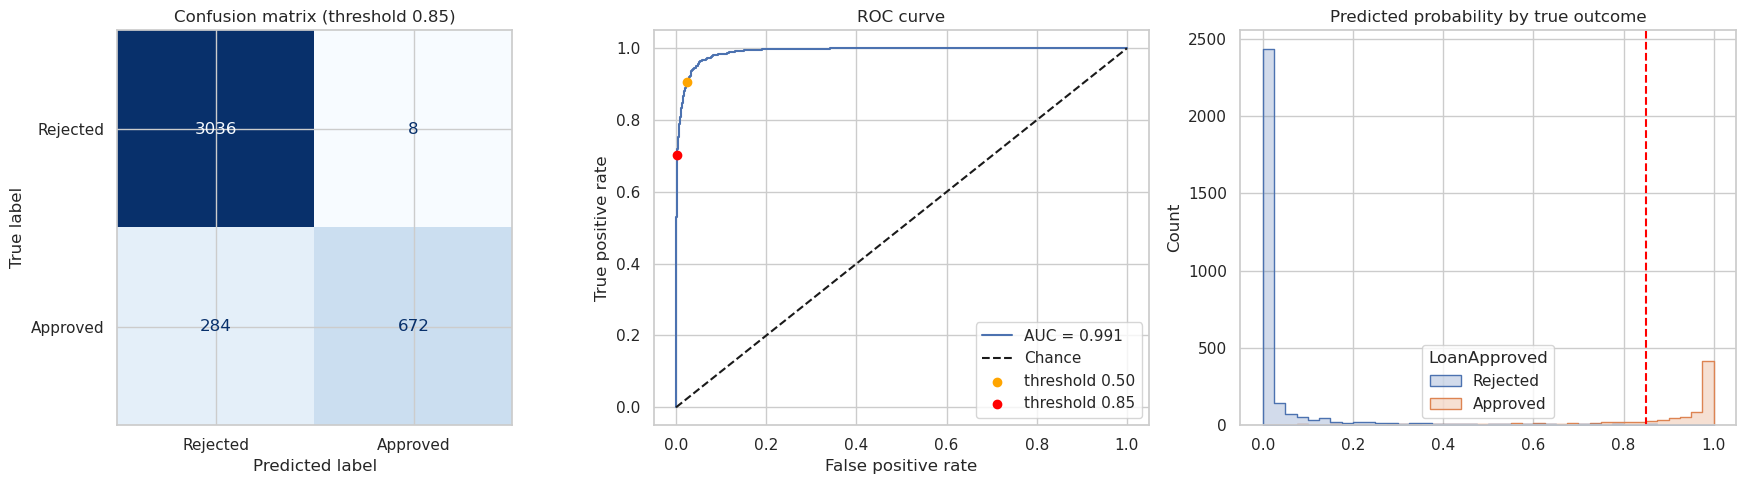

Bad approvals (FP): 8 | Missed good applicants (FN): 284 | Correct approvals (TP): 672


In [ ]:
# Confusion matrix, ROC curve and score distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_tuned),
                       display_labels=["Rejected", "Approved"]).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {best_threshold:.2f})")

fpr, tpr, roc_thr = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
for t, c in [(0.5, "orange"), (best_threshold, "red")]:
    i = np.argmin(np.abs(roc_thr - t))
    axes[1].scatter(fpr[i], tpr[i], color=c, zorder=5, label=f"threshold {t:.2f}")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].legend()

sns.histplot(x=proba, hue=y_test.map({0: "Rejected", 1: "Approved"}), bins=40,
             element="step", ax=axes[2])
axes[2].axvline(best_threshold, color="red", ls="--")
axes[2].set_title("Predicted probability by true outcome")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_tuned).ravel()
print(f"Bad approvals (FP): {fp} | Missed good applicants (FN): {fn} | Correct approvals (TP): {tp}")

In [ ]:
# Performance across segments
seg = X_test.copy()
seg["y"], seg["pred"] = y_test.values, pred_tuned
seg["AgeBand"] = pd.cut(seg["Age"], [17, 29, 39, 49, 59, 100], labels=["18-29", "30-39", "40-49", "50-59", "60+"])
seg["IncomeBand"] = pd.qcut(seg["AnnualIncome"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
seg["EducationLevel"] = seg["EducationLevel"].fillna("Missing")

def segment_table(col):
    g = seg.groupby(col, observed=True)
    return pd.DataFrame({
        "n": g.size(),
        "actual_approval": g["y"].mean(),
        "predicted_approval": g["pred"].mean(),
        "recall": g.apply(lambda d: recall_score(d["y"], d["pred"]) if d["y"].sum() else np.nan),
        "precision": g.apply(lambda d: precision_score(d["y"], d["pred"], zero_division=0) if d["pred"].sum() else np.nan),
        "cost": g.apply(lambda d: business_cost(d["y"], d["pred"])),
    })

for col in ["AgeBand", "IncomeBand", "EducationLevel", "MaritalStatus",
            "EmploymentStatus", "HomeOwnershipStatus", "LoanPurpose"]:
    print(f"\n=== {col} ===")
    display(segment_table(col).round(3))


=== AgeBand ===


,n,actual_approval,predicted_approval,recall,precision,cost
AgeBand,,,,,,
18-29,773,0.1330,0.0850,0.6310,0.9850,0.0560
30-39,1227,0.2200,0.1490,0.6670,0.9840,0.0860
40-49,1197,0.2840,0.2020,0.7090,0.9960,0.0870
50-59,605,0.2840,0.2170,0.7560,0.9920,0.0780
60+,198,0.3590,0.2930,0.7890,0.9660,0.1260



=== IncomeBand ===


,n,actual_approval,predicted_approval,recall,precision,cost
IncomeBand,,,,,,
Q1 low,1000,0.0140,0.0060,0.2860,0.6670,0.0200
Q2,1000,0.0720,0.0340,0.4580,0.9710,0.0440
Q3,1000,0.2270,0.1300,0.5640,0.9850,0.1090
Q4 high,1000,0.6430,0.5100,0.7880,0.9940,0.1510



=== EducationLevel ===


...

,n,actual_approval,predicted_approval,recall,precision,cost
EmploymentStatus,,,,,,
Employed,3402,0.2420,0.1720,0.7030,0.9910,0.0790
Self-Employed,311,0.2640,0.2030,0.7440,0.9680,0.1000
Unemployed,287,0.1740,0.1150,0.6400,0.9700,0.0800



=== HomeOwnershipStatus ===


,n,actual_approval,predicted_approval,recall,precision,cost
HomeOwnershipStatus,,,,,,
Mortgage,1624,0.2490,0.1670,0.6590,0.9820,0.1000
Other,415,0.1730,0.1180,0.6810,1.0000,0.0550
Own,786,0.2650,0.1910,0.7160,0.9930,0.0810
Rent,1175,0.2310,0.1780,0.7640,0.9900,0.0630



=== LoanPurpose ===


,n,actual_approval,predicted_approval,recall,precision,cost
LoanPurpose,,,,,,
Auto,773,0.2430,0.1630,0.6650,0.9920,0.0880
Debt Consolidation,1030,0.2210,0.1610,0.7190,0.9880,0.0720
Education,590,0.2560,0.1800,0.7020,1.0000,0.0760
Home,1196,0.2510,0.1880,0.7370,0.9820,0.0830
Other,411,0.2170,0.1390,0.6290,0.9820,0.0920


In [28]:
# Age and marital status are protected characteristics in lending (e.g. under ECOA).
# Compare how the model's behavior differs from the actual outcomes for each group.
for col in ["AgeBand", "MaritalStatus"]:
    t = segment_table(col)
    t["predicted/actual ratio"] = t["predicted_approval"] / t["actual_approval"]
    print(f"\n=== {col} ===")
    display(t[["n", "actual_approval", "predicted_approval", "predicted/actual ratio", "recall"]].round(3))


=== AgeBand ===


,n,actual_approval,predicted_approval,predicted/actual ratio,recall
AgeBand,,,,,
18-29,773,0.1330,0.0850,0.6410,0.6310
30-39,1227,0.2200,0.1490,0.6780,0.6670
40-49,1197,0.2840,0.2020,0.7120,0.7090
50-59,605,0.2840,0.2170,0.7620,0.7560
60+,198,0.3590,0.2930,0.8170,0.7890



=== MaritalStatus ===


,n,actual_approval,predicted_approval,predicted/actual ratio,recall
MaritalStatus,,,,,
Divorced,506,0.2270,0.1620,0.7130,0.7040
Married,1911,0.2340,0.1720,0.7360,0.7320
Single,1152,0.2400,0.1620,0.6780,0.6590
Widowed,164,0.2440,0.1710,0.7000,0.7000


In [29]:
mask = X_test["EducationLevel"].notna().values
print(f"AUC, all test rows:            {roc_auc_score(y_test, proba):.4f}")
print(f"AUC, excluding missing edu:    {roc_auc_score(y_test[mask], proba[mask]):.4f}")
print(f"Model approvals among {(~mask).sum()} missing-education applicants: {pred_tuned[~mask].sum()}")

AUC, all test rows:            0.9914
AUC, excluding missing edu:    0.9909
Model approvals among 193 missing-education applicants: 0


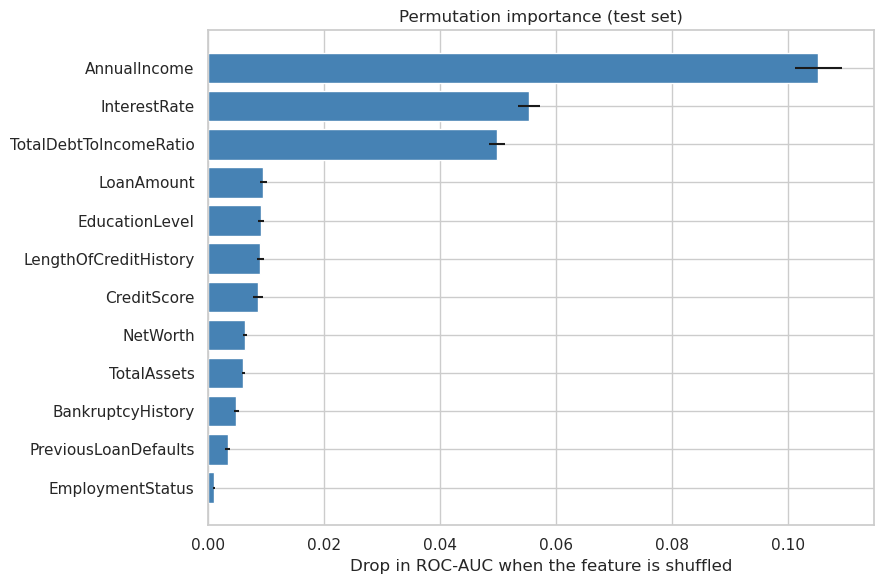

,feature,importance,std
1,AnnualIncome,0.1052,0.0041
28,InterestRate,0.0553,0.0019
30,TotalDebtToIncomeRatio,0.0498,0.0014
6,LoanAmount,0.0096,0.0006
4,EducationLevel,0.0092,0.0006
20,LengthOfCreditHistory,0.0090,0.0006
2,CreditScore,0.0087,0.0009
27,NetWorth,0.0064,0.0003
23,TotalAssets,0.0061,0.0002
16,BankruptcyHistory,0.0049,0.0005


In [30]:
# Permutation importance on the ORIGINAL columns, so one-hot columns aren't scattered across the chart
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
              .sort_values("importance", ascending=False))

top = importance.head(12).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="steelblue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()

display(importance.head(12).round(4))

## Executive Summary

**Bottom line:** A gradient-boosting model can automate loan approval decisions with very high accuracy
(test ROC-AUC 0.991, vs 0.50 for random). Tuned to FinTech Innovations' cost priorities, it makes
almost no bad approvals (precision 98.8%, only 8 of 4,000 applicants wrongly approved) while still
correctly approving 70% of the applicants who deserve approval.

| | Result (test set, 4,000 applicants) |
|---|---|
| Wrongly approved applicants | 8 |
| Wrongly rejected applicants | 284 |
| Cost per applicant vs random decisions | 0.081 vs 1.12 (about 93% lower) |
| Cost per applicant vs default 0.50 threshold | 28% lower |

**What drives decisions:** annual income, the interest rate offered, and debt-to-income ratio.
Age, marital status and dependents have almost no influence on the model.

## Recommendations for Implementation
1. **Use the model as decision support first.** Auto-approve only very high probabilities, auto-reject
   very low ones, and send the middle band to human underwriters. This keeps people involved in the
   284 borderline "missed good applicants".
2. **Confirm the cost ratio.** The 5:1 cost of a bad approval vs a missed good loan is an assumption.
   Ask Finance for real default-loss and lost-margin figures, then re-run the threshold selection.
3. **Check feature availability at decision time.** `InterestRate`, `MonthlyLoanPayment` and
   `TotalDebtToIncomeRatio` depend on loan terms that may only be set after approval. If so, retrain
   without them and measure the performance loss before deploying.
4. **Monitor fairness.** Report approval and recall rates by age band each quarter, since the youngest
   applicants are approved least often relative to their actual approval rate.
5. **Fix the education data capture.** No applicant with missing education was ever approved. Find out
   whether that is a process rule or a data defect before any production use.

## Limitations and Potential Improvements
- **Synthetic data.** Approvals come from a rule plus noise in `CSV_Generation.py`, so 0.99 AUC is far
  higher than real lending data would allow. Re-validate on real historical applications.
- **Assumed costs.** The 5:1 cost ratio and the 0.85 threshold depend on it.
- **Low-income under-approval.** The lowest income quartile has only 1.4% approvals, so the model
  has little data to learn from there. This needs a policy review, not just a modeling fix.
- **Correlated features.** Importance scores are shared between related features, so rankings are
  indicative rather than exact.
- **Next steps:** probability calibration, a three-way decision band (approve / review / reject),
  SHAP explanations for individual decisions (adverse-action reasons), a wider hyperparameter search,
  and a retrain/drift monitoring schedule.